In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats
import seaborn as sns

# Configuração estética dos gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# Carregar o dataset específico da Pergunta 2
processed_path = Path.cwd() / "01_dataset/processed"
q2 = pd.read_excel(processed_path / "q2_daily_ignitions.xlsx")

# Garantir tipos de dados corretos
q2["Date"] = pd.to_datetime(q2["Date"])
q2["Period"] = pd.Categorical(
    q2["Period"], categories=["Pre-2017", "Post-2017"], ordered=True
)
q2["Day_Type"] = pd.Categorical(
    q2["Day_Type"], categories=["Weekday", "Weekend"], ordered=True
)

q2.info()
q2.head()

<class 'pandas.DataFrame'>
RangeIndex: 2897 entries, 0 to 2896
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Concelho               2897 non-null   str           
 1   Date                   2897 non-null   datetime64[us]
 2   Period                 2897 non-null   category      
 3   Daily_Ignitions_Count  2897 non-null   int64         
 4   Day_Type               2897 non-null   category      
dtypes: category(2), datetime64[us](1), int64(1), str(1)
memory usage: 95.5 KB


,Concelho,Date,Period,Daily_Ignitions_Count,Day_Type
0,Chaves,2001-07-21,Pre-2017,1,Weekend
1,Chaves,2001-07-29,Pre-2017,1,Weekend
2,Chaves,2001-08-10,Pre-2017,1,Weekday
3,Chaves,2001-08-13,Pre-2017,1,Weekday
4,Chaves,2001-08-16,Pre-2017,1,Weekday


## 3) Explore Data (Question 2)

**Secondary Research Question 2:** *Did the mean number of daily negligent wildfire ignitions differ significantly between weekends and weekdays in the post-2017 period across the municipalities of Chaves, Montalegre, Ourém and Tomar?*

Before conducting inferential testing, we examine the sample distribution of daily negligent ignitions conditional on active fire days ($Y \ge 1$) across weekdays and weekends, contrasting the pre-2017 and post-2017 cohorts. Because count variables often present positive skewness, both robust measures (median, IQR) and parametric metrics (mean, standard deviation) are reported to fully assess central tendency and dispersion.

In [3]:
# Tabela com resumo estatístico por Período e Tipo de Dia
summary_stats = (
    q2.groupby(["Period", "Day_Type"], observed=False)["Daily_Ignitions_Count"]
    .agg(
        n="count",
        mean="mean",
        std="std",
        median="median",
        iqr=lambda x: x.quantile(0.75) - x.quantile(0.25),
        min="min",
        max="max",
    )
    .reset_index()
)

# Adicionar erro padrão da média (SEM)
summary_stats["sem"] = summary_stats["std"] / np.sqrt(summary_stats["n"])

print("Summary Statistics for Daily Negligent Ignitions:")
display(summary_stats.round(3))

Summary Statistics for Daily Negligent Ignitions:


,Period,Day_Type,n,mean,std,median,iqr,min,max,sem
0,Pre-2017,Weekday,1253,1.505,1.056,1.0,1.0,1,10,0.030
1,Pre-2017,Weekend,505,1.519,1.067,1.0,1.0,1,8,0.047
2,Post-2017,Weekday,802,1.455,1.161,1.0,0.0,1,11,0.041
3,Post-2017,Weekend,337,1.570,1.402,1.0,1.0,1,12,0.076


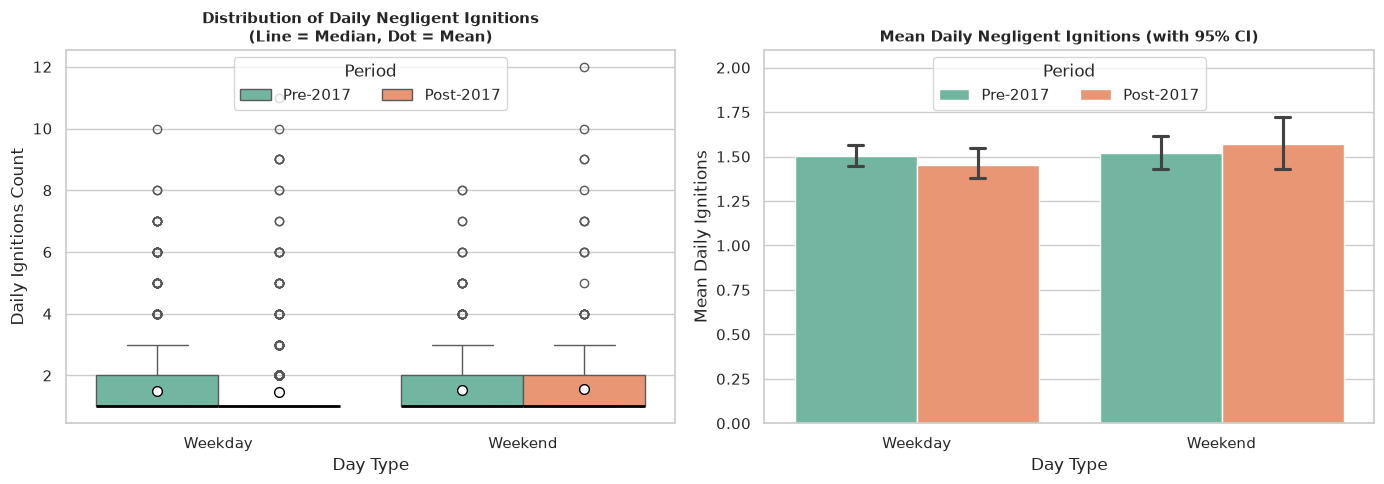

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Boxplot com legenda centrada no topo
sns.boxplot(
    data=q2,
    x="Day_Type",
    y="Daily_Ignitions_Count",
    hue="Period",
    palette="Set2",
    ax=axes[0],
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 7
    },
    medianprops={"color": "black", "linewidth": 2}
)
axes[0].set_title("Distribution of Daily Negligent Ignitions\n(Line = Median, Dot = Mean)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Day Type")
axes[0].set_ylabel("Daily Ignitions Count")
axes[0].legend(title="Period", loc="upper center", ncol=2)

# 2. Barplot de Médias com legenda centrada no topo
sns.barplot(
    data=q2,
    x="Day_Type",
    y="Daily_Ignitions_Count",
    hue="Period",
    palette="Set2",
    errorbar=("ci", 95),
    capsize=0.1,
    ax=axes[1]
)
axes[1].set_title("Mean Daily Negligent Ignitions (with 95% CI)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Day Type")
axes[1].set_ylabel("Mean Daily Ignitions")
axes[1].set_ylim(0, 2.1)
axes[1].legend(title="Period", loc="upper center", ncol=2)

plt.tight_layout()
plt.show()

## 4) Draw Inferences (Question 2)

### Hypothesis Formulation:
We aim to test whether the mean number of daily negligent ignitions differs significantly between weekends and weekdays in the post-2017 period:

- **Null Hypothesis ($H_0$):** $\mu_{\text{Weekend}} - \mu_{\text{Weekday}} = 0$ (There is no difference in the population mean daily negligent ignitions between weekends and weekdays).
- **Alternative Hypothesis ($H_1$):** $\mu_{\text{Weekend}} - \mu_{\text{Weekday}} \neq 0$ (The mean daily negligent ignitions differ between weekends and weekdays).
- **Significance Level:** $\alpha = 0.05$.

In [5]:
# Filtrar para a análise do período pós-2017
post_data = q2[q2["Period"] == "Post-2017"]

weekday_post = post_data[post_data["Day_Type"] == "Weekday"][
    "Daily_Ignitions_Count"
]
weekend_post = post_data[post_data["Day_Type"] == "Weekend"][
    "Daily_Ignitions_Count"
]

# 1. Teste de Levene para Homocedasticidade
levene_stat, levene_p = stats.levene(weekday_post, weekend_post)
print("=== ASSUMPTION CHECK: LEVENE TEST FOR EQUALITY OF VARIANCES ===")
print(f"Statistic: {levene_stat:.4f}, p-value: {levene_p:.4f}")
if levene_p < 0.05:
  print("Result: Variances are significantly different. Welch's t-test is required.\n")
else:
  print("Result: Variances are equal, but Welch's t-test remains robust.\n")

# 2. Execução do Teste t de Welch (equal_var=False)
t_stat, p_val = stats.ttest_ind(weekend_post, weekday_post, equal_var=False)

# Graus de liberdade aproximados de Welch-Satterthwaite
s1, s2 = np.var(weekend_post, ddof=1), np.var(weekday_post, ddof=1)
n1, n2 = len(weekend_post), len(weekday_post)
df_welch = ((s1 / n1 + s2 / n2) ** 2) / (
    ((s1 / n1) ** 2) / (n1 - 1) + ((s2 / n2) ** 2) / (n2 - 1)
)

# Intervalo de Confiança a 95% para a diferença das médias
diff_mean = weekend_post.mean() - weekday_post.mean()
se_diff = np.sqrt(s1 / n1 + s2 / n2)
ci_low, ci_high = stats.t.interval(
    0.95, df=df_welch, loc=diff_mean, scale=se_diff
)

print("=== WELCH'S TWO-SAMPLE T-TEST RESULTS (POST-2017) ===")
print(f"Mean Weekend: {weekend_post.mean():.3f} (n = {n1})")
print(f"Mean Weekday: {weekday_post.mean():.3f} (n = {n2})")
print(f"Difference in Means (Weekend - Weekday): {diff_mean:.3f}")
print(f"Welch t-statistic: {t_stat:.4f}")
print(f"Degrees of Freedom (df): {df_welch:.2f}")
print(f"p-value: {p_val:.4f}")
print(f"95% Confidence Interval for Difference: [{ci_low:.3f}, {ci_high:.3f}]")

=== ASSUMPTION CHECK: LEVENE TEST FOR EQUALITY OF VARIANCES ===
Statistic: 2.0377, p-value: 0.1537
Result: Variances are equal, but Welch's t-test remains robust.

=== WELCH'S TWO-SAMPLE T-TEST RESULTS (POST-2017) ===
Mean Weekend: 1.570 (n = 337)
Mean Weekday: 1.455 (n = 802)
Difference in Means (Weekend - Weekday): 0.115
Welch t-statistic: 1.3223
Degrees of Freedom (df): 538.57
p-value: 0.1866
95% Confidence Interval for Difference: [-0.056, 0.285]


In [6]:
# Complemento analítico: Comparar se a média nos fins de semana caiu de Pre-2017 para Post-2017
weekend_pre = q2[
    (q2["Period"] == "Pre-2017") & (q2["Day_Type"] == "Weekend")
]["Daily_Ignitions_Count"]

t_stat_evol, p_val_evol = stats.ttest_ind(
    weekend_pre, weekend_post, equal_var=False
)
print("=== WELCH'S T-TEST: WEEKENDS PRE-2017 VS POST-2017 ===")
print(
    f"Mean Weekend Pre-2017: {weekend_pre.mean():.3f} vs Post-2017: {weekend_post.mean():.3f}"
)
print(f"t-statistic: {t_stat_evol:.4f}, p-value: {p_val_evol:.4f}")

=== WELCH'S T-TEST: WEEKENDS PRE-2017 VS POST-2017 ===
Mean Weekend Pre-2017: 1.519 vs Post-2017: 1.570
t-statistic: -0.5662, p-value: 0.5715


## 5) Formulate Conclusions (Question 2)

### 5.1 Statistical Decision
- **Significance Level:** $\alpha = 0.05$.
- **Two-Sample Welch's t-test (Post-2017 Weekend vs. Weekday):**
  - Weekday: $\bar{x} = 1.455$ ($s = 1.161$, $\text{median} = 1.0$, $\text{IQR} = 0.0$, $n_1 = 802$)
  - Weekend: $\bar{x} = 1.570$ ($s = 1.402$, $\text{median} = 1.0$, $\text{IQR} = 1.0$, $n_2 = 337$)
  - Difference in sample means ($\bar{x}_{\text{Weekend}} - \bar{x}_{\text{Weekday}}$): $+0.115$ ignitions/day.
  - Test Statistic: Welch's $t(538.57) = 1.3223$, $p\text{-value} = 0.1866$.
  - 95% Confidence Interval for $(\mu_{\text{Weekend}} - \mu_{\text{Weekday}})$: $[-0.056, \, 0.285]$.

Given that the $p\text{-value} = 0.1866$ is strictly greater than the threshold $\alpha = 0.05$, we **fail to reject the null hypothesis ($H_0$)** at the 5% significance level. Consistently, the 95% confidence interval spans zero. Within the observed sample of active fire days, there is insufficient statistical evidence to claim that the population mean number of daily negligent ignitions differs between weekends and weekdays in the post-2017 period across the four monitored municipalities.

### 5.2 Contextual Discussion
1. **Weekend vs. Weekday Patterns:** While the sample mean is nominally higher on weekends by $0.115$ ignitions/day, this variation is fully compatible with expected sampling error under $H_0$. The median daily count remains stable at $1.0$ across both subsets, demonstrating that the typical active day involves isolated single occurrences rather than systematic clusters on non-working days.
2. **Temporal Consistency (Pre vs. Post on Weekends):** The complementary comparison of weekend ignitions between periods yielded $t(657.32) = -0.5662$ ($p = 0.5715$), failing to reveal a statistically detectable difference in mean daily intensity on active weekends between the pre-2017 and post-2017 timeframes.

## 6) Look Back and Ahead (Question 2)

### 6.1 Critical Limitations (Look Back)
1. **Truncated/Conditional Sampling on Active Ignition Days ($Y \ge 1$):**
   - The SGIF database only records days on which at least one fire occurred in a given municipality. Municipal days with zero ignitions ($0$ fires) are unobserved in this aggregated table. As a result, the test evaluates the *operational density of ignitions given that an event occurred*, rather than the unconditional daily risk or overall community fire incidence rate.
2. **Spatial and Temporal Dependency (Assumption of Independence):**
   - The two-sample t-test assumes mutually independent observations. In wildfire dynamics, ignitions occurring in neighboring municipalities (e.g., Chaves and Montalegre) or on consecutive calendar days are often subject to common synoptic meteorological systems (such as heat waves or dry winds), introducing potential unmodeled spatial and temporal autocorrelation.
3. **Distributional Shape and Discrete Nature:**
   - Daily counts are non-negative integers bounded at 1 with right skewness. Although the Central Limit Theorem provides asymptotic robustness for the distribution of the sample mean given the substantial sample sizes ($n_1 = 337, n_2 = 802$), count-based generalized linear models would account more naturally for discrete structures.
4. **Influence of Zero-Area Records:**
   - The cohort includes occurrences with recorded burnt area of $0\text{ ha}$ (such as false alarms or immediate interceptions). Maintaining or excluding these minor records shifts daily event counts, underscoring the sensitivity of empirical metrics to institutional reporting thresholds.

### 6.2 Future Work (Look Ahead)
1. **Full Calendar Reconstruction and Hurdle Models:**
   - Construct an exhaustive daily panel grid (365 days $\times$ 25 years $\times$ 4 municipalities) and estimate a two-part Hurdle or Zero-Inflated Poisson / Negative Binomial model to simultaneously evaluate the probability of ignition occurrence ($P(Y > 0)$) and conditional count severity ($E[Y \mid Y > 0]$).
2. **Integration of Environmental Covariates:**
   - Control for daily meteorological hazard indicators (such as the Fire Weather Index, Drought Code, and wind speed) as interacting covariates to assess whether weekend differences emerge specifically under critical atmospheric thresholds.

---
# EXAM TOOLKIT — t-Tests (Two-Sample, Paired & One-Sample)

Esta secção funciona como um **template direto para o exame** basta mudar o nome do ficheiro, as colunas, os grupos e o tamanho da amostra `n` na primeira célula de código.

## 1. Settings (Change Only These Lines in the Exam)

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats

# ===================== CHANGE ONLY THESE LINES =====================
df_exam = pd.read_excel("01_dataset/processed/q2_daily_ignitions.xlsx")  # filename (.xlsx or pd.read_csv for .csv)

# Optional filter: leave FILTER_COL = None by default so it uses the whole file!
# (Only set e.g. FILTER_COL = "Period" and FILTER_VAL = "Post-2017" if the exam asks to filter a subset)
FILTER_COL = None
FILTER_VAL = None

RESPONSE = "Daily_Ignitions_Count"   # numeric variable to compare
GROUP = "Day_Type"                   # categorical column with the 2 groups
GROUP_1 = "Weekend"                  # Group 1 name (mu_1)
GROUP_2 = "Weekday"                  # Group 2 name (mu_2)

ALTERNATIVE = "two-sided"            # "two-sided" (mu1 != mu2), "greater" (mu1 > mu2), or "less" (mu1 < mu2)
ALPHA = 0.05                         # significance level (0.05 = 5%)

# Random sampling settings:
# Leave n = None if the exam file is ALREADY the sample (e.g. P1_sample.xlsx)!
# Change n = 30 (or another number) if you need to draw a random sample from a full dataset.
n = None                             # None = use all rows | integer (e.g. 30) = draw random sample
n_type = "total"                     # "total" = n rows in total | "per_group" = n rows from EACH group
seed = 42                            # random seed for reproducibility
# ===================================================================

print("Columns in file:", list(df_exam.columns))
print("Unique groups in", GROUP, ":", df_exam[GROUP].dropna().unique())

## 2. Random Sample + Two-Sample t-Test (Welch & Student) + 95% CI

Sorteia `n` linhas **sem reposição** e calcula automaticamente:
- Estatísticas descritivas de cada grupo ($n$, média, desvio-padrão, mediana, IQR).
- **Teste de Levene** para igualdade de variâncias.
- **Welch's t-test** (`equal_var=False`, recomendado por defeito) e **Student's t-test** (`equal_var=True`, variâncias agrupadas $s_p$).
- Valor crítico $t_{\text{crit}}$, $p\text{-value}$ e **Intervalo de Confiança a $(1-\alpha)$** para $\mu_1 - \mu_2$.

In [ ]:
data_sub = df_exam.copy()
if FILTER_COL is not None:
    data_sub = data_sub[data_sub[FILTER_COL] == FILTER_VAL]

data_sub = data_sub[[GROUP, RESPONSE]].dropna()
data_sub = data_sub[data_sub[GROUP].isin([GROUP_1, GROUP_2])]

# Draw random sample (or keep full dataset if n is None)
if n is None:
    sample_df = data_sub.copy()
elif n_type == "total":
    sample_df = data_sub.sample(n=n, random_state=seed)
else:
    sample_df = data_sub.groupby(GROUP, observed=True).sample(n=n, random_state=seed)

g1 = sample_df[sample_df[GROUP] == GROUP_1][RESPONSE].to_numpy()
g2 = sample_df[sample_df[GROUP] == GROUP_2][RESPONSE].to_numpy()

n1, n2 = len(g1), len(g2)
m1, m2 = g1.mean(), g2.mean()
s1, s2 = g1.std(ddof=1), g2.std(ddof=1)
v1, v2 = g1.var(ddof=1), g2.var(ddof=1)
diff = m1 - m2

# 1. Levene's test for equality of variances
lev_stat, lev_p = stats.levene(g1, g2)

# 2. Welch's t-test (unequal variances)
se_welch = np.sqrt(v1 / n1 + v2 / n2)
t_welch, p_welch = stats.ttest_ind(g1, g2, equal_var=False, alternative=ALTERNATIVE)
df_welch = (v1 / n1 + v2 / n2) ** 2 / (((v1 / n1) ** 2) / (n1 - 1) + ((v2 / n2) ** 2) / (n2 - 1))
ci_welch = stats.t.interval(1 - ALPHA, df=df_welch, loc=diff, scale=se_welch)
t_crit_welch = stats.t.ppf(1 - ALPHA / 2, df=df_welch) if ALTERNATIVE == "two-sided" else stats.t.ppf(1 - ALPHA, df=df_welch)

# 3. Student's pooled t-test (equal variances)
df_pool = n1 + n2 - 2
sp = np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / df_pool)
se_pool = sp * np.sqrt(1 / n1 + 1 / n2)
t_pool, p_pool = stats.ttest_ind(g1, g2, equal_var=True, alternative=ALTERNATIVE)
ci_pool = stats.t.interval(1 - ALPHA, df=df_pool, loc=diff, scale=se_pool)
t_crit_pool = stats.t.ppf(1 - ALPHA / 2, df=df_pool) if ALTERNATIVE == "two-sided" else stats.t.ppf(1 - ALPHA, df=df_pool)

desc_table = pd.DataFrame({
    "Group": [GROUP_1, GROUP_2],
    "n": [n1, n2],
    "Mean": [m1, m2],
    "SD": [s1, s2],
    "Variance": [v1, v2],
    "Median": [np.median(g1), np.median(g2)],
    "IQR": [np.percentile(g1, 75) - np.percentile(g1, 25), np.percentile(g2, 75) - np.percentile(g2, 25)],
    "SEM": [s1 / np.sqrt(n1), s2 / np.sqrt(n2)]
})
print("=== DESCRIPTIVE SUMMARY ===")
print(desc_table.round(4).to_string(index=False))
print(f"\nDifference in sample means ({GROUP_1} - {GROUP_2}): {diff:.4f}")

print("\n=== WELCH'S T-TEST (equal_var=False — Default/Robust) ===")
print(f"t({df_welch:.2f}) = {t_welch:.4f} | SE = {se_welch:.4f} | critical t = ±{t_crit_welch:.4f} | p-value = {p_welch:.4f}")
print(f"{int((1-ALPHA)*100)}% CI for (mu1 - mu2): [{ci_welch[0]:.4f}, {ci_welch[1]:.4f}]")
print("Decision:", "REJECT H0" if p_welch < ALPHA else "DO NOT REJECT H0 (inconclusive)")

print("\n=== STUDENT'S POOLED T-TEST (equal_var=True — Equal Variances) ===")
print(f"Pooled SD (sp) = {sp:.4f} | SE = {se_pool:.4f}")
print(f"t({df_pool}) = {t_pool:.4f} | critical t = ±{t_crit_pool:.4f} | p-value = {p_pool:.4f}")
print(f"{int((1-ALPHA)*100)}% CI for (mu1 - mu2): [{ci_pool[0]:.4f}, {ci_pool[1]:.4f}]")

## 3. Assumptions Check (Normality & Homoscedasticity)

- **Independence:** Observações independentes dentro e entre grupos (discute-se pelo desenho do estudo).
- **Normality:** Teste de Shapiro-Wilk em cada grupo ($p > 0.05 \Rightarrow$ não se rejeita normalidade). Se $p < 0.05$, justifica-se sempre pelo **Teorema do Limite Central (CLT)** para amostras razoáveis ($n \ge 30$), que garante a normalidade assintótica das médias amostrais (**nunca usar testes não-paramétricos no exame**).
- **Homoscedasticity (Equal Variances):** Teste de Levene ($p < 0.05 \Rightarrow$ variâncias diferentes $\Rightarrow$ usar **Welch's t-test**, `equal_var=False`).

In [ ]:
for name, arr in [(GROUP_1, g1), (GROUP_2, g2)]:
    sw_p = stats.shapiro(arr).pvalue if len(arr) >= 3 else float("nan")
    skew_val = stats.skew(arr)
    print(f"{name} (n={len(arr)}): Skewness = {skew_val:.3f} | Shapiro-Wilk p = {sw_p:.4f} ({'Normal' if sw_p >= 0.05 else 'Non-normal — justify with Central Limit Theorem (CLT)'})")

var_ratio = max(v1, v2) / min(v1, v2) if min(v1, v2) > 0 else float("nan")
print(f"\nVariance ratio (max/min): {var_ratio:.2f}")
print(f"Levene's test for equal variances: W = {lev_stat:.4f}, p = {lev_p:.4f} -> {'Equal variances supported (Student or Welch t-test)' if lev_p >= 0.05 else 'Unequal variances (MUST use Welch t-test)'}")

## 4. Repeated Random Samples: Effect of Sample Size ($n$) on Power / Rejection Rate

Esta célula sorteia `N_REPEATS` amostras para vários tamanhos `SIZES` (ex.: $n = 10, 30, 60, 150$) e calcula a percentagem de amostras em que $H_0$ é rejeitado e o erro-padrão médio.
- Com $n$ maior, o erro-padrão diminui ($\text{SE} \propto 1/\sqrt{n}$), os intervalos de confiança estreitam e a **potência do teste ($1-\beta$)** aumenta.

In [ ]:
# ===================== CHANGE HERE =====================
SIZES = [10, 30, 60, 150]   # sample sizes to compare
N_REPEATS = 30              # number of random samples for each size
# =======================================================

sim_rows = []
for sz in SIZES:
    rejections, valid = 0, 0
    p_list, se_list = [], []
    for r in range(N_REPEATS):
        if n_type == "total":
            if sz > len(data_sub):
                continue
            s = data_sub.sample(n=sz, random_state=r)
        else:
            min_grp = data_sub[GROUP].value_counts().min()
            if sz > min_grp:
                continue
            s = data_sub.groupby(GROUP, observed=True).sample(n=sz, random_state=r)
        a1 = s[s[GROUP] == GROUP_1][RESPONSE].to_numpy()
        a2 = s[s[GROUP] == GROUP_2][RESPONSE].to_numpy()
        if len(a1) < 2 or len(a2) < 2 or (a1.var(ddof=1) == 0 and a2.var(ddof=1) == 0):
            continue
        t_r, p_r = stats.ttest_ind(a1, a2, equal_var=False, alternative=ALTERNATIVE)
        se_r = np.sqrt(a1.var(ddof=1) / len(a1) + a2.var(ddof=1) / len(a2))
        valid += 1
        rejections += int(p_r < ALPHA)
        p_list.append(p_r)
        se_list.append(se_r)
    sim_rows.append({
        "n": sz,
        "n_type": n_type,
        "valid_samples": valid,
        "rejections": rejections,
        "rejection_rate (%)": round(100 * rejections / valid, 1) if valid else None,
        "mean_SE": round(float(np.mean(se_list)), 4) if se_list else None,
        "median_p_value": round(float(np.median(p_list)), 4) if p_list else None
    })

print(pd.DataFrame(sim_rows).to_string(index=False))

## 5. Power & Minimum Sample Size Calculator (If Asked in the Exam)

Se uma pergunta do exame pedir:
1. Qual a **potência ($1-\beta$)** do teste para detetar uma diferença verdadeira $\Delta = |\mu_1 - \mu_2|$ com $n$ observações por grupo?
2. Qual o **tamanho de amostra mínimo ($n$ por grupo)** necessário para atingir $80\%$ (ou $90\%$) de potência?

In [ ]:
# ===================== CHANGE HERE =====================
DELTA_TRUE = 0.25          # hypothetical true difference between means |mu1 - mu2| to detect
SD_ESTIMATE = 1.25         # estimated standard deviation (e.g. pooled SD from sample)
N_PER_GROUP = 100          # sample size per group to check power
TARGET_POWER = 0.80        # desired power (e.g. 0.80 for 80%)
# =======================================================

# 1. Power for a given N_PER_GROUP
se_power = SD_ESTIMATE * np.sqrt(2 / N_PER_GROUP)
df_power = 2 * N_PER_GROUP - 2
t_crit_pow = stats.t.ppf(1 - ALPHA / 2, df=df_power)
ncp = DELTA_TRUE / se_power  # non-centrality parameter
power_val = 1 - stats.nct.cdf(t_crit_pow, df=df_power, nc=ncp) + stats.nct.cdf(-t_crit_pow, df=df_power, nc=ncp)
beta_val = 1 - power_val

# 2. Required N per group for TARGET_POWER (normal approximation + t refinement)
z_alpha = stats.norm.ppf(1 - ALPHA / 2)
z_beta = stats.norm.ppf(TARGET_POWER)
n_req = int(np.ceil(2 * (SD_ESTIMATE * (z_alpha + z_beta) / DELTA_TRUE) ** 2))

print(f"For Delta = {DELTA_TRUE}, SD = {SD_ESTIMATE}, n = {N_PER_GROUP} per group:")
print(f"  -> Statistical Power (1 - beta) = {power_val:.4f} ({power_val*100:.1f}%)")
print(f"  -> Type II Error probability (beta) = {beta_val:.4f} ({beta_val*100:.1f}%)")
print(f"\nMinimum sample size required for {TARGET_POWER*100:.0f}% power: n ≈ {n_req} per group ({2*n_req} total)")

## 6. Bonus: One-Sample t-Test & Paired t-Test (Quick Snippets)

Caso no exame saia um **t-test para uma única média** ($H_0: \mu = \mu_0$) ou para **amostras emparelhadas** ($H_0: \mu_D = 0$, ex.: *Before vs. After* no mesmo município/indivíduo):

In [ ]:
# --- A) ONE-SAMPLE T-TEST (H0: mu = MU_0) ---
MU_0 = 1.50  # hypothesized population mean
t_1s, p_1s = stats.ttest_1samp(g1, popmean=MU_0, alternative="two-sided")
ci_1s = stats.t.interval(1 - ALPHA, df=len(g1)-1, loc=g1.mean(), scale=g1.std(ddof=1)/np.sqrt(len(g1)))
print(f"[One-Sample t-test] Mean = {g1.mean():.4f} vs mu_0 = {MU_0}: t({len(g1)-1}) = {t_1s:.4f}, p = {p_1s:.4f}, 95% CI = [{ci_1s[0]:.4f}, {ci_1s[1]:.4f}]")

# --- B) PAIRED T-TEST (H0: mu_diff = 0 on matched pairs) ---
# Example with equal-length paired arrays pair_1 and pair_2:
m_len = min(len(g1), len(g2))
pair_1, pair_2 = g1[:m_len], g2[:m_len]
d_pair = pair_1 - pair_2
t_pair, p_pair = stats.ttest_rel(pair_1, pair_2, alternative="two-sided")
ci_pair = stats.t.interval(1 - ALPHA, df=m_len-1, loc=d_pair.mean(), scale=d_pair.std(ddof=1)/np.sqrt(m_len))
print(f"[Paired t-test] Mean diff = {d_pair.mean():.4f}: t({m_len-1}) = {t_pair:.4f}, p = {p_pair:.4f}, 95% CI = [{ci_pair[0]:.4f}, {ci_pair[1]:.4f}]")

## 7. Exam Answer Template for Two-Sample t-Test (English — Fill in the Numbers)

**1. Terminology:**
- Let $\mu_1$ be the population mean of `[response]` in `[Group 1]` and $\mu_2$ be the population mean of `[response]` in `[Group 2]`.
- Sample sizes: $n_1 = \dots$ and $n_2 = \dots$ observations (drawn at random without replacement from `[dataset]`).
- Significance level: $\alpha = 0.05$.

**2. Hypotheses:**
- **$H_0$:** $\mu_1 - \mu_2 = 0$ (or $\mu_1 = \mu_2$ — the population means are equal in both groups).
- **$H_1$:** $\mu_1 - \mu_2 \neq 0$ (two-sided; or $\mu_1 > \mu_2$ / $\mu_1 < \mu_2$ if one-sided).

**3. Methodology & Assumptions:**
- We use a two-sample **Welch's t-test** (which does not assume equal variances across groups; Student's pooled t-test is also reported for comparison).
- **Assumptions:**
  1. *Independence:* Observations are independent within and between groups (discuss potential spatial/temporal clustering if observational).
  2. *Normality:* Shapiro-Wilk $p = \dots$ in Group 1 and $p = \dots$ in Group 2. With sample sizes $n_1, n_2 \ge 30$, the **Central Limit Theorem (CLT)** guarantees that the sampling distribution of the means is approximately normal even if the raw data are skewed.
  3. *Homoscedasticity:* Levene's test yields $W = \dots, p = \dots$ (variance ratio $= \dots$). Welch's t-test adjusts the degrees of freedom ($df = \dots$) to remain valid regardless of variance inequality.

**4. Test Statistic, p-value & Confidence Interval:**
- Sample means: $\bar{x}_1 = \dots$ ($s_1 = \dots$) and $\bar{x}_2 = \dots$ ($s_2 = \dots$), difference $\bar{x}_1 - \bar{x}_2 = \dots$.
- Welch's $t(\text{df} = \dots) = \dots$, $p\text{-value} = \dots$ (critical $t_{0.975} = \pm \dots$).
- 95% Confidence Interval for $(\mu_1 - \mu_2)$: $[\dots, \, \dots]$.

**5. Conclusion in Context:**
- *If $p < 0.05$:* "Since $p = \dots < \alpha = 0.05$ (and the 95% CI does not contain 0), we **reject $H_0$**. There is statistically significant evidence that the true mean `[response]` differs between `[Group 1]` and `[Group 2]`."
- *If $p \ge 0.05$:* "Since $p = \dots \ge \alpha = 0.05$ (and the 95% CI contains 0), we **fail to reject $H_0$**. The test is **inconclusive**: the sample does not provide sufficient statistical evidence that the true mean `[response]` differs between `[Group 1]` and `[Group 2]`."

**6. Effect of Sample Size & Power:**
- "When the sample size increases from $n = \dots$ to $n = \dots$, the standard error of the difference decreases ($\text{SE} \propto 1/\sqrt{n}$), narrowing the confidence interval and increasing the **statistical power ($1 - \beta$)** of the test (the rejection rate across repeated random samples changes from $\dots\%$ to $\dots\%$). With small samples, Type II errors (failing to detect a true difference) are more likely."